# Machine-Learning Practice 5
## Myrzakassymov Azizkhan

### Objective
The goal of this task is to understand fairness in production machine learning systems,
where models directly impact real people and business decisions.
In research, models are usually evaluated using overall performance metrics (e.g.,
accuracy). However, in production, it is critical to ensure that models perform consistently
across different groups of users, and do not unintentionally disadvantage certain
populations.


### 1. Train any classification model (e.g., Logistic Regression or Random Forest)
 on the German Credit Dataset (From Practice Task -3)

https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
statlog_german_credit_data = fetch_ucirepo(id=144) 
  
# data (as pandas dataframes) 
X = pd.DataFrame(statlog_german_credit_data.data.features)
y = pd.DataFrame(statlog_german_credit_data.data.targets)
  
display(X, y)

,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,A14,12,A32,A42,1736,A61,A74,3,A92,A101,4,A121,31,A143,A152,1,A172,1,A191,A201
996,A11,30,A32,A41,3857,A61,A73,4,A91,A101,4,A122,40,A143,A152,1,A174,1,A192,A201
997,A14,12,A32,A43,804,A61,A75,4,A93,A101,4,A123,38,A143,A152,1,A173,1,A191,A201
998,A11,45,A32,A43,1845,A61,A73,4,A93,A101,4,A124,23,A143,A153,1,A173,1,A192,A201


,class
0,1
1,2
2,1
3,1
4,2
...,...
995,1
996,1
997,1
998,2


In [3]:
# Preprocessing the data, making pipelines and preprocessor

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.impute import KNNImputer
from sklearn.pipeline import Pipeline

cat = X.select_dtypes('str').columns.to_list()
num = X.select_dtypes('number').columns.to_list()

cat_pipeline = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]
)

num_pipeline = Pipeline(
    steps=[
        ('imputer', KNNImputer(weights='distance')),
        ('scaler', StandardScaler())
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', cat_pipeline, cat),
        ('numerical', num_pipeline, num)
    ]
)

In [39]:
# Main pipeline for Random Forest classifier
# Splitting data

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.utils import column_or_1d

rf_pipeline = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('encoder', RandomForestClassifier(n_estimators=120, criterion='entropy'))
    ]
)

X_train, X_test, y_train, y_test = train_test_split(X, column_or_1d(y), train_size=0.8)


In [41]:
# Training Random Forest

rf_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('encoder', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[1,2]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Attribute1','Attribute2','Attribute3',...,'Attribute18','Attribute19', 'Attribute20']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

### 2. Identify and use:

A. Explicit sensitive features (required)
 - Sex
 - Age (convert into groups, e.g., < 30 vs ≥ 30)
 
B. Proxy features (choose at least TWO)

Select features that may indirectly reflect socio-economic status, for example:
 - Job
 - Housing
 - Credit history
 - Savings account
 - Purpose of loan

We will use Sex, which is already divided into two groups, and age, that I will divie into group <25 and >=25.

Sex is Attribute 9:  (qualitative)
Personal status and sex
 - A91 : male   : divorced/separated
 - A92 : female : divorced/separated/married
 - A93 : male   : single
 - A94 : male   : married/widowed
 - A95 : female : single

and Age is Attribute 13: (numerical)

I will divide them into four groups: 
- Male <25
- Male >=25
- Female <25 
- Female >=25

In [25]:
# A. 
from itertools import product

test_data = pd.DataFrame(X_test, columns=X.columns)

sex_conditions = {
    'Male'   : ( test_data['Attribute9'].isin(['A91', 'A93', 'A94']) ),
    'Female' : ( test_data['Attribute9'].isin(['A92', 'A95']) )
}
age_conditions = {
    '<25 y.o.' : (test_data['Attribute13'] < 25), 
    '>=25 y.o.' : (test_data['Attribute13'] >= 25)
}


groups_a = {}
for (sex_label, sex_mask), (age_label, age_mask) in product(
    sex_conditions.items(), age_conditions.items() # Cartesian product, or Matrix of conditions for my groups
): 
    groups_a[sex_label + ', ' + age_label] = test_data[sex_mask & age_mask] # Dictionary of groups and their conditions

groups_a.keys()

dict_keys(['Male, <25 y.o.', 'Male, >=25 y.o.', 'Female, <25 y.o.', 'Female, >=25 y.o.'])

In this practice I will choose Job, Credit History and Saving Account. 

Job is Attribute 17: (qualitative)
- A171 : unemployed / unskilled  - non-resident
- A172 : unskilled - resident
- A173 : skilled employee / official
- A174 : management / self-employed/ highly qualified employee / officer

Credit History is Attribute 3: (qualitative)
- A30 : no credits taken / all credits paid back duly
- A31 : all credits at this bank paid back duly
- A32 : existing credits paid back duly till now
- A33 : delay in paying off in the past
- A34 : critical account / other credits existing (not at this bank)

Saving Account is Attibute 6:  (qualitative)
- A61 :          ... <  100 DM
- A62 :   100 <= ... <  500 DM
- A63 :   500 <= ... < 1000 DM
- A64 :          .. >= 1000 DM
- A65 :   unknown/ no savings account


Job will save its attributes, but in this study I will divide Credit History and Saving Account into 2 and 3 groups respectively,

for Credit history it will be bad credit history and good (From A33-34 to A30-31) and for Saving account it will be from ... < 500 DM and 500 <= ... and Unknown.


In [28]:
# And other groups, they will be marked as groups_b in code

job_conditions = {
    'Unemployed/unskilled - non-resident' : (test_data['Attribute17'].isin(['A171'])),
    'Unskilled - resident'                : (test_data['Attribute17'].isin(['A172'])), 
    'Skilled employee/official'           : (test_data['Attribute17'].isin(['A173'])), 
    'Management/self-employed etc.'       : (test_data['Attribute17'].isin(['A174']))  
}

credit_conditions = {
    'Good' : (test_data['Attribute3'].isin(['A30', 'A31'])),
    'Bad'  : (test_data['Attribute3'].isin(['A32', 'A33', 'A34']))
}

saving_conditions = {
    '<500 DM' : (test_data['Attribute6'].isin(['A61', 'A62'])),
    '500 DM<=' : (test_data['Attribute6'].isin(['A63', 'A64'])),
    'Unknown' : (test_data['Attribute6'].isin(['A65']))
}

groups_b = {}
for (job_label, job_mask), (credit_label, credit_mask), (saving_label, saving_mask) in product(
    job_conditions.items(), credit_conditions.items(), saving_conditions.items()
):
    groups_b[job_label + ', ' + credit_label + ', ' + saving_label] = test_data[job_mask & credit_mask & saving_mask]

groups_b.keys()

dict_keys(['Unemployed/unskilled - non-resident, Good, <500 DM', 'Unemployed/unskilled - non-resident, Good, 500 DM<=', 'Unemployed/unskilled - non-resident, Good, Unknown', 'Unemployed/unskilled - non-resident, Bad, <500 DM', 'Unemployed/unskilled - non-resident, Bad, 500 DM<=', 'Unemployed/unskilled - non-resident, Bad, Unknown', 'Unskilled - resident, Good, <500 DM', 'Unskilled - resident, Good, 500 DM<=', 'Unskilled - resident, Good, Unknown', 'Unskilled - resident, Bad, <500 DM', 'Unskilled - resident, Bad, 500 DM<=', 'Unskilled - resident, Bad, Unknown', 'Skilled employee/official, Good, <500 DM', 'Skilled employee/official, Good, 500 DM<=', 'Skilled employee/official, Good, Unknown', 'Skilled employee/official, Bad, <500 DM', 'Skilled employee/official, Bad, 500 DM<=', 'Skilled employee/official, Bad, Unknown', 'Management/self-employed etc., Good, <500 DM', 'Management/self-employed etc., Good, 500 DM<=', 'Management/self-employed etc., Good, Unknown', 'Management/self-employed

### 3. For each selected feature:
- split the test dataset into groups
- make predictions for each group
- compute at least metrics ( Accuracy, Recall and others)


In [ ]:
# For groups A

from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score

y_pred = rf_pipeline.predict(X_test)
print(f'In general, accuracy is {accuracy_score(y_test, y_pred)}\n')

acc_a = {} # these are for visualizations
prec_a = {}
f1_a = {}
size_a = {}

for key, group in groups_a.items():
    y_true = y.loc[groups_a[key].index]
    y_pred = rf_pipeline.predict(group)

    acc_a[key] = accuracy_score(y_true, y_pred)
    prec_a[key] = precision_score(y_true, y_pred)
    f1_a[key] = f1_score(y_true, y_pred)
    size_a[key] = len(group)

    print(f'For group "{key}":')
    print(f'Accuracy: {acc_a[key]}')
    print(f'Precision: {prec_a[key]}')
    print(f'F1-score: {f1_a[key]}')
    print(f'Size of the group: {size_a[key]} \n')

In general, accuracy is 0.73

For group "Male, <25 y.o.":
Accuracy: 0.8461538461538461
Precision: 0.75
F1-score: 0.75
Size of the group: 13 

For group "Male, >=25 y.o.":
Accuracy: 0.92
Precision: 0.9270833333333334
F1-score: 0.9468085106382979
Size of the group: 125 

For group "Female, <25 y.o.":
Accuracy: 1.0
Precision: 1.0
F1-score: 1.0
Size of the group: 23 

For group "Female, >=25 y.o.":
Accuracy: 1.0
Precision: 1.0
F1-score: 1.0
Size of the group: 39 



In [ ]:
# Now for groups B

y_pred = rf_pipeline.predict(X_test)
print(f'In general, accuracy is {accuracy_score(y_test, y_pred)}\n')

for key, group in groups_b.items():
    if len(group) > 0:
        y_true = y.loc[groups_b[key].index]
        y_pred = rf_pipeline.predict(group)

        print(f'For group "{key}":')
        print(f'Accuracy: {accuracy_score(y_true, y_pred)}')
        if len(group) > 1: # Because one cannot divide by 0 :( 
            print(f'Precision: {precision_score(y_true, y_pred)}')
            print(f'F1-score: {f1_score(y_true, y_pred)}')
        print(f'Size of the group: {len(y_true)} \n')
        
    else:
        print(f'group "{key}" is empty\n')

In general, accuracy is 0.73

For group "Unemployed/unskilled - non-resident, Good, <500 DM":
Accuracy: 1.0
Size of the group: 1 

group "Unemployed/unskilled - non-resident, Good, 500 DM<=" is empty

group "Unemployed/unskilled - non-resident, Good, Unknown" is empty

group "Unemployed/unskilled - non-resident, Bad, <500 DM" is empty

For group "Unemployed/unskilled - non-resident, Bad, 500 DM<=":
Accuracy: 1.0
Size of the group: 1 

For group "Unemployed/unskilled - non-resident, Bad, Unknown":
Accuracy: 1.0
Precision: 1.0
F1-score: 1.0
Size of the group: 2 

For group "Unskilled - resident, Good, <500 DM":
Accuracy: 0.6666666666666666
Precision: 0.5
F1-score: 0.6666666666666666
Size of the group: 3 

group "Unskilled - resident, Good, 500 DM<=" is empty

For group "Unskilled - resident, Good, Unknown":
Accuracy: 1.0
Size of the group: 1 

For group "Unskilled - resident, Bad, <500 DM":
Accuracy: 0.9666666666666667
Precision: 1.0
F1-score: 0.9787234042553191
Size of the group: 30 

F

I decided to make vizualizations, but only for groups A, because there's lots of groups in B, and most of the sizes are telling us that results are not representative.

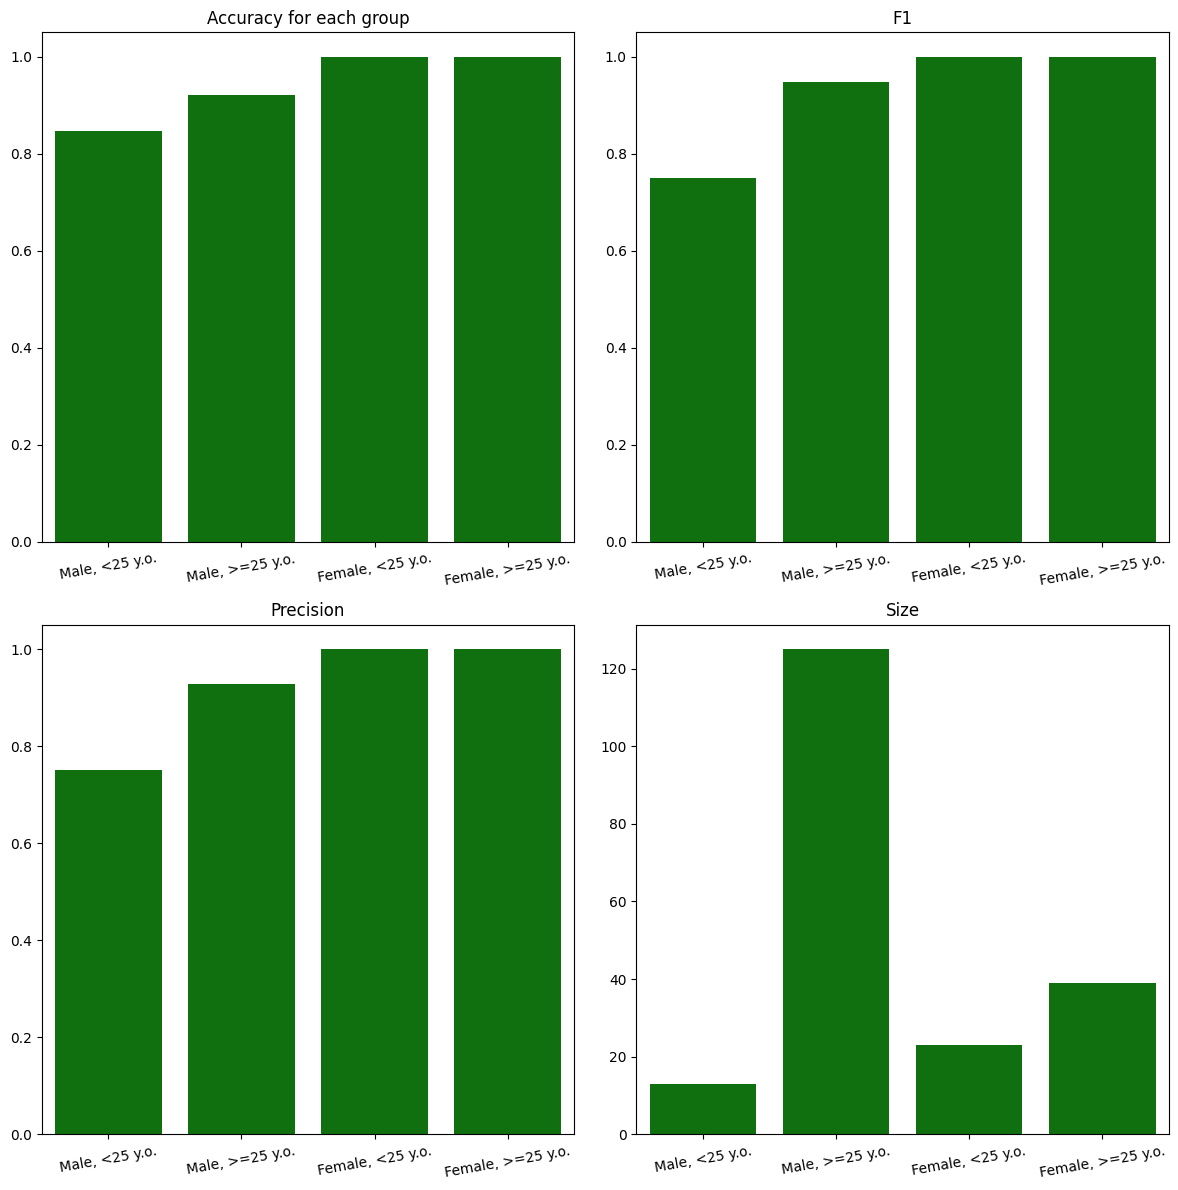

In [ ]:
# Vizualization group
import seaborn as sns

fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(12, 12), dpi=100)
axes = ax.flatten()

# Accuracy
sns.barplot( x=acc_a.keys(), y=acc_a.values(), ax = axes[0], color='green')
axes[0].set_title('Accuracy for each group')
axes[0].tick_params(axis='x', rotation=10)

# F1
sns.barplot( x=f1_a.keys(), y=f1_a.values(), ax = axes[1], color='green')
axes[1].set_title('F1')
axes[1].tick_params(axis='x', rotation=10)

# Precision
sns.barplot( x=prec_a.keys(), y=prec_a.values(), ax = axes[2], color='green')
axes[2].set_title('Precision')
axes[2].tick_params(axis='x', rotation=10)

# Size 
sns.barplot( x=size_a.keys(), y=size_a.values(), ax = axes[3], color='green')
axes[3].set_title('Size')
axes[3].tick_params(axis='x', rotation=10)

plt.tight_layout()
plt.show()

Analysis Questions
- Does model performance differ across groups for each feature?
- Which groups consistently receive worse predictions?
- Do proxy features reveal additional bias compared to Sex/Age?
- Why might these differences occur?
- Why is this critical in real-world systems like credit scoring?

Answers:
Size of dataset, and groups are not large enough (except for Male, >=25 y.o.) to judge if model makes better predictions for some groups and worse for others.

Though, in our example Male, <25 y.o. had way poorer predictions than groups with females, that model predicted correctly in 100%, which can be a certain basis for the evidence that this model predicts female groups better.

Proxy features do reveal additional bias because most of the samples has size of 1 or 2.

It is critical for real world-systems because of ethics, and we generally have to make our models more robust.